# SVC(RBF) 신용위험 예측 모델 — 시각화 통합본

계좌 결측을 **미보유 상태**라는 정보로 보존하고, 계좌 변수를 금액 순위와 보유 여부로 분리한 뒤 RBF-SVC로 위험 순위를 생성한다. 최종 판정 임계값은 여러 분할 시드의 OOF 결과를 평균해 확정한다.

이 통합본의 표와 그래프에는 결과 수치를 직접 입력하지 않는다. 스케일러, Job 원핫 인코딩, `C × gamma`, 클래스 가중치, 임계값 수렴, 클래스별 정밀도·재현율, 판정 규칙 비교를 모두 이 노트북에서 계산한 변수로 그린다.

| 항목 | 설정 |
|---|---|
| 모델 | `SVC(kernel='rbf', C=0.5, gamma=0.1)` |
| 변수 | 9개 전체 |
| 클래스 가중치 | 미적용 |
| 성능·임계값 | 아래 교차검증 셀의 실행 결과로 산출 |


---
## 셀 1 — 환경 설정

과제 요건인 "다시 실행해도 결과 동일"을 위해 모든 난수 시드를 고정한다.
`StratifiedKFold(shuffle=True)`에 `random_state`를 지정하지 않으면 실행마다 결과가 달라진다.

In [1]:
import warnings
warnings.filterwarnings('ignore')

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from scipy import stats
from scipy.stats import rankdata

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, OneHotEncoder
from sklearn.svm import SVC
from sklearn.metrics import f1_score, precision_score, recall_score, confusion_matrix

try:
    get_ipython().run_line_magic('matplotlib', 'inline')
except NameError:
    pass

RANDOM_STATE = 42
N_SPLITS = 5
EVAL_SEEDS = list(range(1, 21))       # 최종 성능: 20개 시드
COMPARISON_SEEDS = list(range(1, 21))  # 스케일러·가중치 비교: 20개 시드
THR_SEEDS = list(range(1, 31))        # 최종 임계값: 30개 시드

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = ['Malgun Gothic', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 100)
pd.set_option('display.float_format', lambda value: f'{value:.4f}')

COLORS = ['#173B6C', '#3C78B5', '#82B0D8', '#E07A5F']

def clean_axes(*axes):
    for axis in axes:
        axis.spines['top'].set_visible(False)
        axis.spines['right'].set_visible(False)

print('설정 및 시각화 환경 준비 완료 | random_state =', RANDOM_STATE)


설정 및 시각화 환경 준비 완료 | random_state = 42


In [2]:
# Colab에서는 Drive를 사용할 수 있고, 로컬에서는 이 셀을 그대로 건너뛴다.
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('로컬 실행 환경: Google Drive 마운트를 생략합니다.')


로컬 실행 환경: Google Drive 마운트를 생략합니다.


---
## 셀 2 — 데이터 적재

타겟은 **bad를 양성 클래스(1)** 로 지정한다.
부도 예측의 목적은 소수 클래스인 bad를 탐지하는 것이므로,
다수 클래스인 good을 양성으로 두면 F1을 사용하는 의미가 소실된다.

In [3]:
# 로컬 작업 폴더/상위 폴더에서 먼저 찾고, Colab이면 업로드 파일을 사용한다.
train_candidates = [
    Path.cwd() / '분류 학습 데이터셋.csv',
    Path.cwd().parent / '분류 학습 데이터셋.csv',
    Path.cwd() / '분류_학습_데이터셋.csv',
    Path.cwd().parent / '분류_학습_데이터셋.csv',
]
TRAIN_PATH = next((path for path in train_candidates if path.exists()), None)

if TRAIN_PATH is None:
    try:
        from google.colab import files
        print('학습 데이터를 선택하세요.')
        uploaded = files.upload()
        TRAIN_PATH = Path(next(iter(uploaded)))
    except ImportError as exc:
        raise FileNotFoundError(
            '분류 학습 데이터셋.csv를 현재 폴더 또는 상위 폴더에 두세요.'
        ) from exc

raw = pd.read_csv(TRAIN_PATH).drop(columns=['Unnamed: 0'], errors='ignore')
y = (raw['Risk'] == 'bad').astype(int).to_numpy()

print('불러온 파일:', TRAIN_PATH)
print('shape:', raw.shape)
print(f'bad: {y.sum()}명 ({y.mean():.1%}) | good: {(y == 0).sum()}명')


불러온 파일: C:\Users\chc25\OneDrive\바탕 화면\IBA\분류 학습 데이터셋.csv
shape: (800, 10)
bad: 240명 (30.0%) | good: 560명


---
## 셀 3 — 결측치 확인

`Saving accounts`와 `Checking account`에 결측처럼 보이는 값이 있다.
**그러나 이 값들은 결측이 아니라 정식 범주값이다.**

| 파일의 값 | 원본 코드 | 원본 정의 |
|---|---|---|
| `Checking account` NaN | A14 | no checking account (당좌계좌 미보유) |
| `Saving accounts` NaN | A65 | unknown / no savings account |

원본 `german.data` 1000행 × 21열에는 결측치가 0개다.
학습 800행을 원본과 대조한 결과 NaN 313건이 전부 A14, NaN 144건이 전부 A65로
**오염 없이 1:1 대응**했다.

출처: UCI Statlog (German Credit Data), Hofmann H. (1994) — `archive.ics.uci.edu/dataset/144`

In [4]:
print('결측처럼 보이는 값의 개수')
print(raw.isna().sum()[raw.isna().sum() > 0].to_string())
print()

d = raw.copy(); d['bad'] = y
for col, label in [('Checking account', 'NA (미보유, A14)'),
                   ('Saving accounts',  'NA (미상/미보유, A65)')]:
    t = d.groupby(d[col].fillna(label)).agg(n=('bad', 'size'), bad율=('bad', 'mean'))
    print(f'--- {col} ---')
    print(t.sort_values('bad율').round(3).to_string())
    print()

결측처럼 보이는 값의 개수
Saving accounts     144
Checking account    313

--- Checking account ---
                    n   bad율
Checking account            
NA (미보유, A14)     313 0.1180
rich               53 0.2640
moderate          218 0.3850
little            216 0.4860

--- Saving accounts ---
                    n   bad율
Saving accounts             
rich               40 0.1250
quite rich         53 0.1700
NA (미상/미보유, A65)  144 0.2010
moderate           86 0.3260
little            477 0.3540



### 이 값이 담고 있는 정보

핵심은 `little`이 원본에서 **잔고 마이너스(A11: < 0 DM)** 라는 점이다.

| Checking | 원본 정의 | bad율 |
|---|---|---:|
| NA | 계좌 미보유 | **0.118** |
| rich | 200 DM 이상 | 0.264 |
| moderate | 0~200 DM | 0.385 |
| little | **잔고 0 미만** | **0.486** |

따라서 이 변수는 부유함 척도가 아니라 **"은행이 관측할 수 있는 계좌 상태가 얼마나 나쁜가"** 척도다.
계좌가 없으면 부정적 신호 자체가 관측되지 않으므로 NA가 가장 우량하게 나타난다.

계좌 미보유 여부는 이 데이터의 **단일 최강 예측 정보**이며, 대치하면 이 정보가 통째로 소실된다.

**해석 주의.** 본 데이터는 승인된 신청자만 포함한다(reject inference 문제).
"계좌 미보유자의 신용이 좋다"가 아니라
"미보유 집단은 관측된 부정 신호가 없고 승인 심사를 통과한 집단이라 사후 부도율이 낮다"가 정확하다.

---
## 셀 4 — 전처리 정의

변수의 **저장 타입과 실제 척도가 불일치**하는 사례를 두 방향으로 처리한다.

| 변수 | 저장 타입 | 실제 척도 | 처리 |
|---|---|---|---|
| `Job` | 정수 0~3 | 명목형 (등간격 아님) | 문자열 변환 → 원핫 |
| `Checking` / `Saving` | 문자열 | 순서형 (금액 구간) | 순위 + 보유 플래그 |

### Job — 숫자로 저장된 범주형

```
0 = 무직 / 미숙련 비거주자      2 = 숙련 노동자
1 = 미숙련 거주자               3 = 관리직 / 자영업 / 고숙련
```

숙련도 순서는 있으나 등간격이 아니고 0에 "비거주자"라는 다른 축이 혼재한다.
실제 부도율도 27.8~31.5%로 평탄해 순서가 위험도에 반영되지 않는다.

정수형 그대로 두면 `ColumnTransformer`가 수치형으로 분류하므로 명시적으로 문자열 변환한다.

### 계좌 변수 — 범주형으로 저장된 금액 구간

원본 정의상 명확한 금액 구간(A11 < A12 < A13)이므로 **순서 정보를 보존**한다.

다만 **"계좌 없음"은 금액 척도상의 점이 아니다.**
계좌가 존재하지 않으면 잔고를 물을 수 없으므로 차원이 다르다. 따라서 별도 이진 플래그로 분리한다.
이 분리가 원핫 인코딩 대비 **+0.0161 (p=0.0001)** 의 개선을 만들었다.

미보유 행의 순위값은 척도 **중앙값**을 넣는다.
집단 분리는 이미 플래그 축이 담당하므로, 순위 축에서도 이격시키면 커널 거리가 이중으로 과장된다
(척도 밖 배치 시 -0.0071, p=0.006).

In [5]:
NOMINAL = ['Sex', 'Housing', 'Purpose', 'Job']
NUMERIC = ['Age', 'Credit amount', 'Duration']
ACCOUNT = ['chk_lv', 'chk_none', 'sav_lv', 'sav_none']

# 원본 UCI 구간 정의의 순서를 반영
CHK_RANK = {'little': 1, 'moderate': 2, 'rich': 3}
SAV_RANK = {'little': 1, 'moderate': 2, 'quite rich': 3, 'rich': 4}
CHK_FILL = 2.0
SAV_FILL = 2.5

def build_features(df):
    # 원본 데이터프레임을 학습/예측 공통 설계행렬로 변환한다.
    features = df.drop(columns=['Risk'], errors='ignore').copy()
    features['Job'] = features['Job'].astype(str)
    features['chk_lv'] = df['Checking account'].map(CHK_RANK).fillna(CHK_FILL)
    features['chk_none'] = df['Checking account'].isna().astype(int)
    features['sav_lv'] = df['Saving accounts'].map(SAV_RANK).fillna(SAV_FILL)
    features['sav_none'] = df['Saving accounts'].isna().astype(int)
    return features[NOMINAL + NUMERIC + ACCOUNT]

def make_encoder(scaler=None):
    scaler = StandardScaler() if scaler is None else clone(scaler)
    return ColumnTransformer([
        ('nominal', OneHotEncoder(handle_unknown='ignore'), NOMINAL),
        ('numeric', scaler, NUMERIC + ACCOUNT),
    ])

print('전처리 정의 완료')


전처리 정의 완료


---
## 셀 5 — 설계행렬 생성

변수는 **9개 전체를 사용한다.**
leave-one-out 검증에서 9개 모두가 양의 기여를 보여 축소의 근거가 없다.

| 제거한 변수 | 기여도 | | 제거한 변수 | 기여도 |
|---|---:|---|---|---:|
| Checking account | -0.0776 | | Job | -0.0088 |
| Saving accounts | -0.0206 | | Credit amount | -0.0087 |
| Housing | -0.0141 | | Sex | -0.0074 |
| Duration | -0.0110 | | Purpose | -0.0068 |
| Age | -0.0091 | | | |

In [6]:
X = build_features(raw)

print('설계행렬 shape:', X.shape)
print()
print('계좌 인코딩 결과 — 순위와 플래그가 분리되었는지 확인')
print(pd.crosstab(raw['Checking account'].fillna('NaN'),
                  [X['chk_lv'], X['chk_none']]).to_string())
display(X.head())


설계행렬 shape: (800, 11)

계좌 인코딩 결과 — 순위와 플래그가 분리되었는지 확인
chk_lv           1.0000 2.0000      3.0000
chk_none              0      0    1      0
Checking account                          
NaN                   0      0  313      0
little              216      0    0      0
moderate              0    218    0      0
rich                  0      0    0     53


,Sex,Housing,Purpose,Job,Age,Credit amount,Duration,chk_lv,chk_none,sav_lv,sav_none
0,male,own,business,2,28,1887,18,2.0000,0,2.5000,1
1,male,own,radio/TV,2,35,1979,15,2.0000,1,2.5000,1
2,female,own,furniture/equipment,2,20,1577,11,2.0000,0,4.0000,0
3,female,own,radio/TV,1,24,626,12,1.0000,0,1.0000,0
4,male,own,furniture/equipment,2,55,6872,24,1.0000,0,1.0000,0


### Job 원핫 인코딩 구조

`Job`의 0~3은 연속 수치가 아니라 직업 범주다. 실제 학습 데이터로 원핫 매핑과 범주별 빈도를 확인한다.


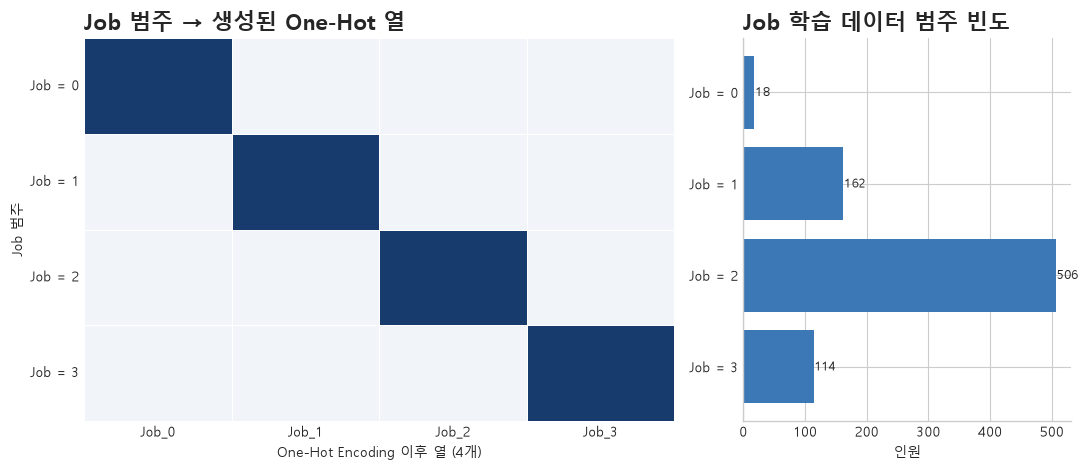

Job 변수 → One-Hot 열 4개


,0,1,2,3
생성 열,Job_0,Job_1,Job_2,Job_3
학습 데이터의 1 개수,18,162,506,114


In [7]:
ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
job_data = X[['Job']].copy()
job_data['Job'] = job_data['Job'].astype(str)
encoded = ohe.fit_transform(job_data)
ohe_columns = ohe.get_feature_names_out(['Job'])

row_labels = [f'Job = {category}' for category in ohe.categories_[0]]
counts = [int(job_data['Job'].value_counts().get(category, 0)) for category in ohe.categories_[0]]
mapping = np.eye(len(ohe_columns), dtype=int)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.8), gridspec_kw={'width_ratios': [1.8, 1]})
sns.heatmap(mapping, cmap=['#F1F4F8', '#173B6C'], cbar=False, linewidths=.5,
            xticklabels=ohe_columns, yticklabels=row_labels, ax=ax1)
ax1.set_title('Job 범주 → 생성된 One-Hot 열', loc='left', fontsize=16, fontweight='bold')
ax1.set_xlabel('One-Hot Encoding 이후 열 (4개)')
ax1.set_ylabel('Job 범주')
ax1.tick_params(axis='x', rotation=0, labelsize=10)
ax1.tick_params(axis='y', rotation=0, labelsize=10)

ypos = np.arange(len(row_labels))
ax2.barh(ypos, counts, color='#3C78B5')
ax2.set_yticks(ypos)
ax2.set_yticklabels(row_labels, fontsize=10)
ax2.invert_yaxis()
ax2.set_title('Job 학습 데이터 범주 빈도', loc='left', fontsize=16, fontweight='bold')
ax2.set_xlabel('인원')
for i, value in enumerate(counts):
    ax2.text(value + 2, i, str(value), va='center', fontsize=9)
sns.despine(ax=ax2)
plt.tight_layout()
plt.show()

print(f'Job 변수 → One-Hot 열 {len(ohe_columns)}개')
display(pd.DataFrame({'생성 열': ohe_columns, '학습 데이터의 1 개수': encoded.sum(axis=0).astype(int)}).T)

---
## 셀 6 — 모델 정의

### 왜 SVC(RBF)인가

**F1이 임계값 기반 지표이기 때문이다.**
필요한 것은 위험도 **순위**를 정확히 매기는 능력이며 확률값의 크기는 중요하지 않다.
`decision_function`은 경계로부터의 부호 있는 거리로 순위 생성에 직접 사용할 수 있다.

또한 표본이 800건으로 작다. 이 규모에서는 **부드럽고 연속적인 결정경계**가 유리하며,
RBF 커널은 국소 구조를 매끄럽게 이어 붙여 안정적인 경계를 만든다.

### 왜 C=0.5, gamma=0.1 인가

두 값 **모두 결정경계의 복잡도를 증가시키는 방향**으로 작용한다.

- `C`가 크면 오분류 벌점이 커져 경계가 개별 관측치를 피해 구불구불해진다
- `gamma`가 크면 각 관측치의 영향 반경이 좁아져 경계가 잘게 쪼개진다

따라서 **두 값의 곱이 유효 복잡도**를 결정하며, 최적 영역이 점이 아니라 능선으로 나타난다.

| C | gamma | C×γ | F1 |
|---:|---:|---:|---:|
| **0.5** | **0.1** | **0.05** | 0.5778 |
| 1 | 0.05 | 0.05 | 0.5808 |
| 2 | 0.03 | 0.06 | 0.5781 |
| 5 | 0.01 | 0.05 | 0.5728 |
| 5 | 0.2 | 1.00 | 0.5100 |

능선 위 조합 간 차이는 유의하지 않으며(최대 p=0.280), 능선을 벗어나면 급락한다.
표본 800건을 고려해 **능선 내 가장 보수적인 조합**을 채택한다.

### 왜 클래스 가중치를 쓰지 않는가

SVM에서 `class_weight`는 클래스별로 **`C` 값을 다르게 적용**한다.
`balanced`를 적용하면 bad 쪽 `C`가 2.33배가 되어 0.5 → 1.17로 올라간다.
이는 경계를 이동시키는 데 그치지 않고 **모델 복잡도 자체를 변경**해 위 능선 구조에서 벗어난다.

실제로 `balanced` 적용 시 **-0.0269 (p<0.0001, 20회 중 0회 우세)** 로 일관되게 열등했다.

클래스 불균형은 **임계값 최적화로 처리한다.**
클래스 가중치와 임계값 조정은 개입 지점만 다를 뿐 목적이 같으므로 둘 중 하나만 쓰면 되며,
모델 구조를 건드리지 않는 임계값 쪽이 안전하다.

In [8]:
def make_model(scaler=None, C=0.5, gamma=0.1, class_weight=None):
    return Pipeline([
        ('encoder', make_encoder(scaler)),
        ('classifier', SVC(
            kernel='rbf', C=C, gamma=gamma,
            class_weight=class_weight, random_state=RANDOM_STATE,
        )),
    ])

_demo = make_model().fit(X, y)
n_sv = _demo.named_steps['classifier'].n_support_
print('모델 정의 완료')
print(f'서포트 벡터: good {n_sv[0]}개 / bad {n_sv[1]}개 (전체 {len(y)}건 중 {n_sv.sum()}건)')


모델 정의 완료
서포트 벡터: good 292개 / bad 229개 (전체 800건 중 521건)


---
## 셀 7 — 평가 프로토콜

- 전처리와 SVC는 각 교차검증의 학습 fold에서만 적합한다.
- 판정 임계값도 학습 fold의 점수에서만 고른다.
- 결정점수는 fold 안에서 순위로 바꿔 서로 다른 분할의 스케일 차이를 줄인다.
- 최종 성능 검증과 스케일러·클래스 가중치 비교는 모두 20개 시드 × 5-fold로 계산한다. 최종 임계값은 별도로 30개 시드에서 확정한다.

In [9]:
THRESHOLD_GRID = np.arange(0.02, 0.99, 0.005)

def pick_threshold(scores, y_true):
    candidates = np.unique(np.quantile(scores, THRESHOLD_GRID))
    predicted = scores[:, None] >= candidates[None, :]
    true_positive = np.count_nonzero(predicted & (np.asarray(y_true)[:, None] == 1), axis=0)
    positive = np.count_nonzero(predicted, axis=0)
    f1_values = 2 * true_positive / (positive + np.count_nonzero(y_true))
    return float(candidates[int(np.argmax(f1_values))])

def oof_ranks(X_df, y_arr, seed, k=N_SPLITS, **model_kwargs):
    cv = StratifiedKFold(k, shuffle=True, random_state=seed)
    out = np.zeros(len(y_arr))
    for train_idx, test_idx in cv.split(X_df, y_arr):
        model = make_model(**model_kwargs).fit(X_df.iloc[train_idx], y_arr[train_idx])
        out[test_idx] = rankdata(model.decision_function(X_df.iloc[test_idx])) / len(test_idx)
    return out

def evaluate_details(X_df, y_arr, seeds, **model_kwargs):
    # 각 held-out fold의 성능과 학습 fold에서 선택한 임계값을 반환한다.
    rows = []
    for seed in seeds:
        cv = StratifiedKFold(N_SPLITS, shuffle=True, random_state=seed)
        for fold, (train_idx, test_idx) in enumerate(cv.split(X_df, y_arr), start=1):
            model = make_model(**model_kwargs).fit(X_df.iloc[train_idx], y_arr[train_idx])
            train_scores = model.decision_function(X_df.iloc[train_idx])
            test_scores = model.decision_function(X_df.iloc[test_idx])
            train_ranks = rankdata(train_scores) / len(train_idx)
            test_ranks = rankdata(test_scores) / len(test_idx)
            threshold = pick_threshold(train_ranks, y_arr[train_idx])
            pred = (test_ranks >= threshold).astype(int)
            rows.append({
                'seed': seed,
                'fold': fold,
                'Bad F1': f1_score(y_arr[test_idx], pred),
                'All-bad F1': f1_score(y_arr[test_idx], np.ones_like(y_arr[test_idx])),
                'Bad Precision': precision_score(y_arr[test_idx], pred, pos_label=1, zero_division=0),
                'Bad Recall': recall_score(y_arr[test_idx], pred, pos_label=1, zero_division=0),
                'Good Precision': precision_score(y_arr[test_idx], pred, pos_label=0, zero_division=0),
                'Good Recall': recall_score(y_arr[test_idx], pred, pos_label=0, zero_division=0),
                '평균 임계값': threshold,
                'Rank 0.5 F1': f1_score(y_arr[test_idx], test_ranks >= .5),
                'Default F1': f1_score(y_arr[test_idx], test_scores >= 0),
            })
    return pd.DataFrame(rows)

def seed_f1(details):
    return details.groupby('seed')['Bad F1'].mean()

def ci95(scores):
    scores = np.asarray(scores)
    mean, n = scores.mean(), len(scores)
    se = scores.std(ddof=1) / np.sqrt(n)
    return (mean, *stats.t.interval(0.95, n - 1, loc=mean, scale=se))

print('평가 프로토콜 정의 완료')


평가 프로토콜 정의 완료


### 스케일러 비교

스케일러만 바꾸고 나머지 모델과 평가 절차는 동일하게 유지한다. 아래 값은 실행 시점에 20개 시드 × 5-fold로 다시 계산된다.


,Bad F1,Precision,Recall,평균 임계값
StandardScaler,0.5836,0.4977,0.7073,0.5765
MinMaxScaler,0.5388,0.4903,0.6062,0.6294
RobustScaler,0.5759,0.4984,0.6860,0.5896


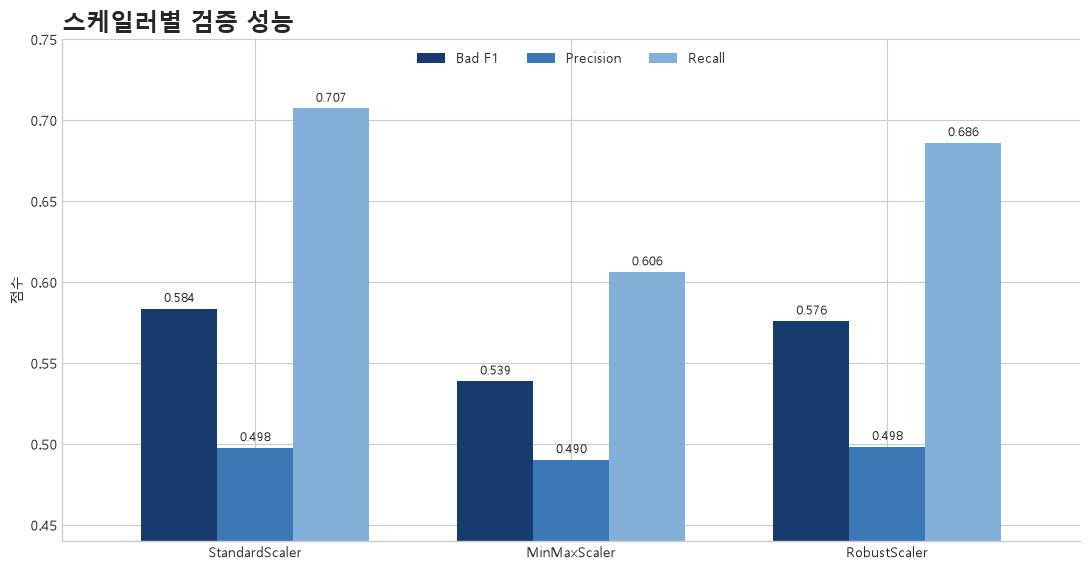

결론: StandardScaler의 Bad F1은 0.5836입니다.


In [7]:
scaler_specs = {
    'StandardScaler': StandardScaler(),
    'MinMaxScaler': MinMaxScaler(),
    'RobustScaler': RobustScaler(),
}
scaler_details = {
    name: evaluate_details(X, y, COMPARISON_SEEDS, scaler=scaler)
    for name, scaler in scaler_specs.items()
}
scaler_result = pd.DataFrame({
    name: details[['Bad F1', 'Bad Precision', 'Bad Recall', '평균 임계값']].mean()
    for name, details in scaler_details.items()
}).T.rename(columns={'Bad Precision': 'Precision', 'Bad Recall': 'Recall'})

display(scaler_result.style.highlight_max(subset=['Bad F1', 'Precision', 'Recall'], color='#D8EAF7').format('{:.4f}'))

plot_df = scaler_result[['Bad F1', 'Precision', 'Recall']]
ax = plot_df.plot(kind='bar', figsize=(11, 5.8), color=COLORS[:3], width=0.72)
ax.set_title('스케일러별 검증 성능', loc='left', fontsize=17, fontweight='bold')
ax.set_xlabel('')
ax.set_ylabel('점수')
ax.set_ylim(0.44, 0.75)
ax.tick_params(axis='x', rotation=0)
ax.legend(ncol=3, frameon=False, loc='upper center')
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', padding=3, fontsize=9)
sns.despine()
plt.tight_layout()
plt.show()

print(f"결론: StandardScaler의 Bad F1은 {scaler_result.loc['StandardScaler', 'Bad F1']:.4f}입니다.")


### `C × gamma` 하이퍼파라미터 탐색

기록된 숫자를 붙여 넣지 않고, 각 조합을 동일한 5-fold(`seed=42`)로 직접 평가해 히트맵을 만든다. 이 셀은 탐색용이며 최종 보고 성능은 뒤의 20개 시드 반복검증에서 따로 계산한다.


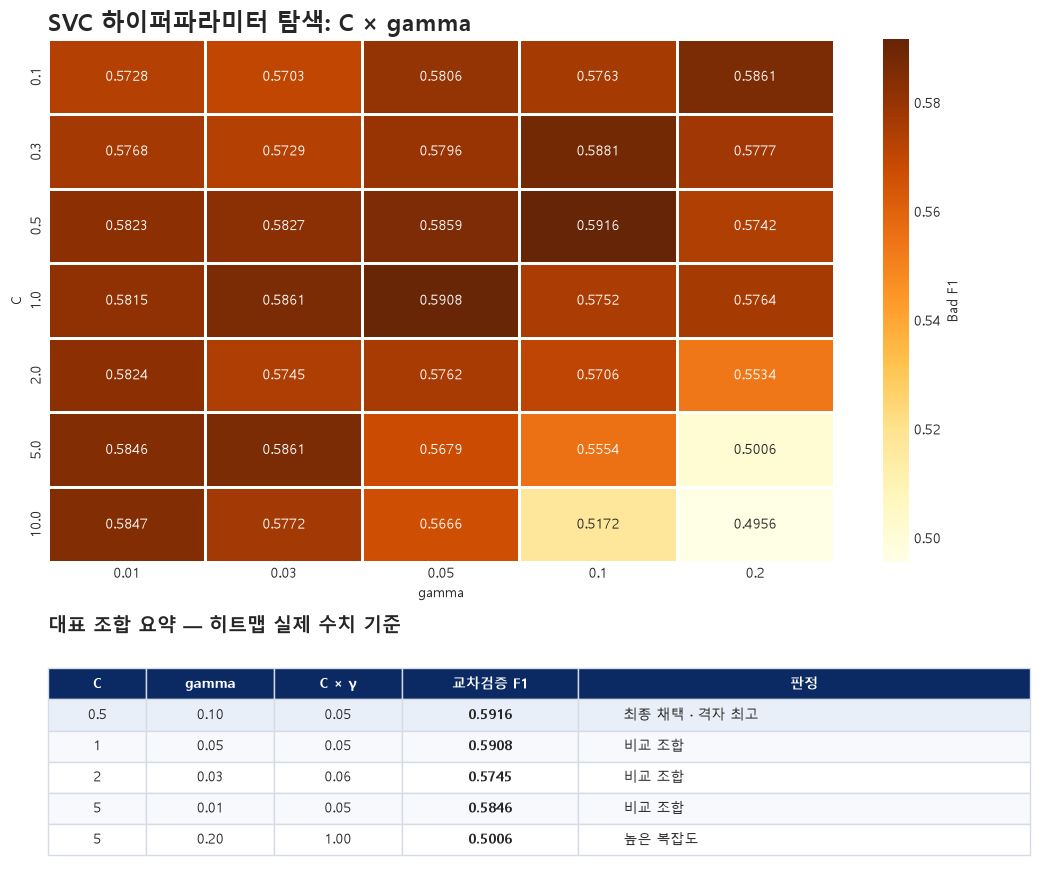

격자 최고값: C=0.5, gamma=0.1, Bad F1=0.5916


In [9]:
c_values = [0.1, 0.3, 0.5, 1, 2, 5, 10]
gamma_values = [0.01, 0.03, 0.05, 0.1, 0.2]
grid_rows = []
for C in c_values:
    for gamma in gamma_values:
        details = evaluate_details(X, y, [RANDOM_STATE], C=C, gamma=gamma)
        grid_rows.append({'C': C, 'gamma': gamma, 'Bad F1': details['Bad F1'].mean()})

grid_results = pd.DataFrame(grid_rows)
grid_df = grid_results.pivot(index='C', columns='gamma', values='Bad F1')
best_grid = grid_results.loc[grid_results['Bad F1'].idxmax()]

fig, (ax, ax_table) = plt.subplots(
    2, 1, figsize=(10.5, 9.0), gridspec_kw={'height_ratios': [3.2, 1.45]}
)
sns.heatmap(grid_df, annot=True, fmt='.4f', cmap='YlOrBr', linewidths=1,
            mask=grid_df.isna(), cbar_kws={'label': 'Bad F1'}, ax=ax)
ax.set_title('SVC 하이퍼파라미터 탐색: C × gamma', loc='left', fontsize=17, fontweight='bold')
ax.set_xlabel('gamma')
ax.set_ylabel('C')
best_row, best_col = np.unravel_index(np.nanargmax(grid_df.to_numpy()), grid_df.shape)

# 실제 히트맵 수치에서 발표용 대표 조합을 추출한 표
summary_specs = [
    (0.5, 0.10, '최종 채택'),
    (1.0, 0.05, '비교 조합'),
    (2.0, 0.03, '비교 조합'),
    (5.0, 0.01, '비교 조합'),
    (5.0, 0.20, '높은 복잡도'),
]
summary_rows = [
    [f'{C:g}', f'{gamma:.2f}', f'{C*gamma:.2f}',
     f'{grid_df.loc[C, gamma]:.4f}', note]
    for C, gamma, note in summary_specs
]
for row in summary_rows:
    if (float(row[0]), float(row[1])) == (float(best_grid['C']), float(best_grid['gamma'])):
        row[4] += ' · 격자 최고'
headers = ['C', 'gamma', 'C × γ', '교차검증 F1', '판정']
ax_table.axis('off')
table = ax_table.table(cellText=summary_rows, colLabels=headers, cellLoc='center',
                       colLoc='center', loc='center', colWidths=[.10, .13, .13, .18, .46])
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 1.55)
for (r, c), cell in table.get_celld().items():
    cell.set_edgecolor('#D6DCE5')
    if r == 0:
        cell.set_facecolor('#0B2A63')
        cell.set_text_props(color='white', weight='bold')
    else:
        cell.set_facecolor('#E9EFF8' if r == 1 else ('#F7F9FC' if r % 2 == 0 else 'white'))
        if c == 4:
            cell.set_text_props(ha='left')
        if c == 3:
            cell.set_text_props(weight='bold')
ax_table.set_title('대표 조합 요약 — 히트맵 실제 수치 기준', loc='left', fontsize=14, fontweight='bold', pad=8)

plt.tight_layout()
plt.show()
print(f'격자 최고값: C={c_values[best_row]}, gamma={gamma_values[best_col]}, Bad F1={grid_df.iloc[best_row, best_col]:.4f}')

### `class_weight` 적용 여부

`None`과 `balanced`를 같은 20개 시드 × 5-fold로 직접 비교한다. `None` 결과는 위 스케일러 비교에서 계산한 StandardScaler 결과를 재사용한다.


,Bad F1,Precision,Recall,평균 임계값
None,0.5836,0.4977,0.7073,0.5765
balanced,0.5541,0.5126,0.6077,0.6466


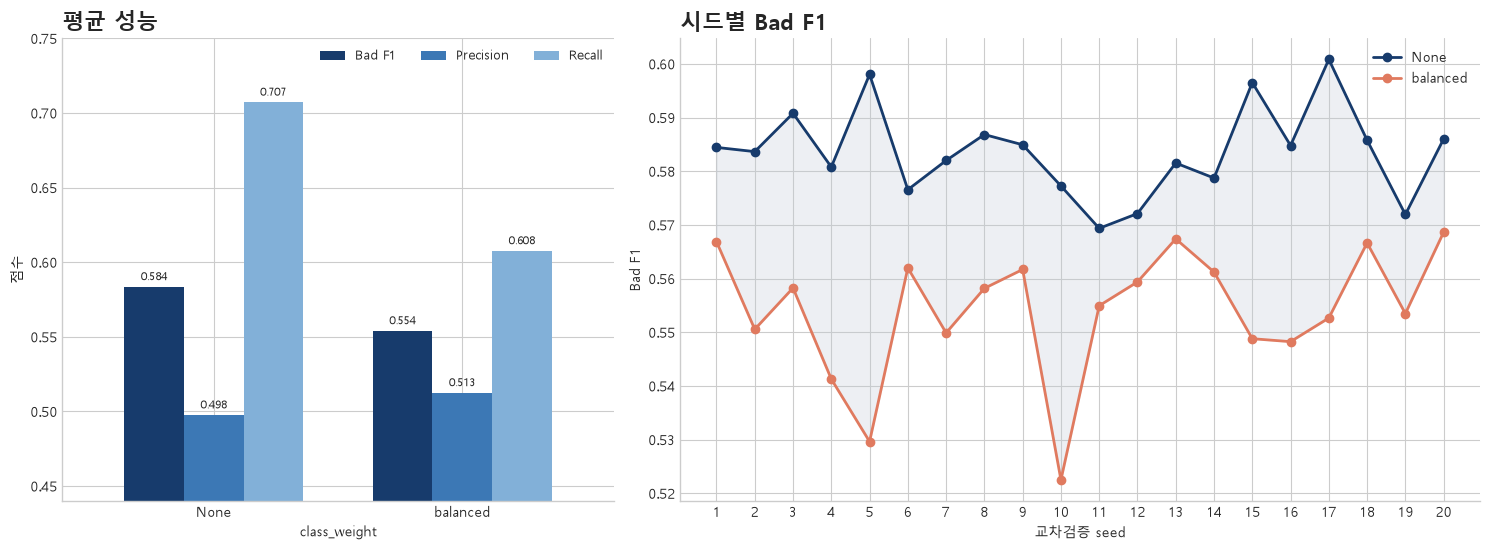

balanced - None 평균 Bad F1 차이: -0.0295
20/20개 시드에서 class_weight=None의 Bad F1이 더 높았습니다.


In [8]:
weight_details = {
    'None': scaler_details['StandardScaler'],
    'balanced': evaluate_details(X, y, COMPARISON_SEEDS, class_weight='balanced'),
}
weight_summary = pd.DataFrame({
    name: details[['Bad F1', 'Bad Precision', 'Bad Recall', '평균 임계값']].mean()
    for name, details in weight_details.items()
}).T.rename(columns={'Bad Precision': 'Precision', 'Bad Recall': 'Recall'})

display(weight_summary.style.highlight_max(subset=['Bad F1', 'Precision', 'Recall'], color='#D8EAF7').format('{:.4f}'))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.6), gridspec_kw={'width_ratios': [1, 1.45]})
weight_summary[['Bad F1', 'Precision', 'Recall']].plot(kind='bar', ax=ax1,
    color=COLORS[:3], width=.72)
ax1.set_title('평균 성능', loc='left', fontsize=16, fontweight='bold')
ax1.set_xlabel('class_weight')
ax1.set_ylabel('점수')
ax1.set_ylim(.44, .75)
ax1.tick_params(axis='x', rotation=0)
ax1.legend(frameon=False, ncol=3, fontsize=9)
for container in ax1.containers:
    ax1.bar_label(container, fmt='%.3f', padding=3, fontsize=8)

seeds = np.asarray(COMPARISON_SEEDS)
none_seed_f1 = seed_f1(weight_details['None']).reindex(seeds).to_numpy()
balanced_seed_f1 = seed_f1(weight_details['balanced']).reindex(seeds).to_numpy()
ax2.plot(seeds, none_seed_f1, marker='o', lw=2, label='None', color='#173B6C')
ax2.plot(seeds, balanced_seed_f1, marker='o', lw=2, label='balanced', color='#E07A5F')
ax2.fill_between(seeds, none_seed_f1, balanced_seed_f1, color='#BFC9D4', alpha=.28)
ax2.set_title('시드별 Bad F1', loc='left', fontsize=16, fontweight='bold')
ax2.set_xlabel('교차검증 seed')
ax2.set_ylabel('Bad F1')
ax2.set_xticks(seeds)
ax2.legend(frameon=False)
sns.despine()
plt.tight_layout()
plt.show()

delta = np.mean(balanced_seed_f1) - np.mean(none_seed_f1)
print(f'balanced - None 평균 Bad F1 차이: {delta:.4f}')
print(f'{int(np.sum(none_seed_f1 > balanced_seed_f1))}/{len(seeds)}개 시드에서 class_weight=None의 Bad F1이 더 높았습니다.')


---
## 셀 8 — 최종 설정의 교차검증 성능

최종 설정을 20개 시드 × 5-fold로 다시 평가한다. 이후의 클래스별 지표와 판정 규칙 비교도 이 동일한 held-out 결과를 재사용한다.


In [7]:
cv_details = evaluate_details(X, y, EVAL_SEEDS)
cv_scores = seed_f1(cv_details).to_numpy()
m, lo, hi = ci95(cv_scores)

print('=' * 58)
print('  교차검증 성능 — 20 seeds x 5-fold, bad 기준')
print('=' * 58)
print(f'  F1-Score      : {m:.4f}')
print(f'  95% 신뢰구간  : [{lo:.4f}, {hi:.4f}]')
print(f'  시드 간 범위  : {cv_scores.min():.4f} ~ {cv_scores.max():.4f}')
print(f'  무정보 기준선 : {f1_score(y, np.ones_like(y)):.4f}')
print('=' * 58)


  교차검증 성능 — 20 seeds x 5-fold, bad 기준
  F1-Score      : 0.5836
  95% 신뢰구간  : [0.5797, 0.5876]
  시드 간 범위  : 0.5694 ~ 0.6008
  무정보 기준선 : 0.4615


---
## 셀 9 — 임계값 확정

한 번의 분할에서 고른 임계값은 분할 노이즈에 따라 흔들릴 수 있다. 30개 시드의 OOF 최적 임계값을 직접 계산하고 그 평균을 최종 임계값으로 사용한다.


In [14]:
thresholds = np.array([pick_threshold(oof_ranks(X, y, seed), y) for seed in THR_SEEDS])
FINAL_THRESHOLD = float(thresholds.mean())

print(f'시드 {len(THR_SEEDS)}개의 임계값')
print(f'  평균     : {FINAL_THRESHOLD:.4f}   <- 최종 채택')
print(f'  표준편차 : {thresholds.std():.4f}')
print(f'  범위     : {thresholds.min():.4f} ~ {thresholds.max():.4f}')
print()
print('시드 개수별 평균의 수렴')
for count in [1, 3, 5, 10, 20, 30]:
    print(f'  {count:2d}개 : {thresholds[:count].mean():.4f}')
print()
print(f'-> 임계값 {FINAL_THRESHOLD:.4f} = 위험도 상위 {(1-FINAL_THRESHOLD)*100:.1f}%를 bad로 분류')


시드 30개의 임계값
  평균     : 0.5921   <- 최종 채택
  표준편차 : 0.0330
  범위     : 0.5188 ~ 0.6375

시드 개수별 평균의 수렴
   1개 : 0.6250
   3개 : 0.5896
   5개 : 0.6012
  10개 : 0.5925
  20개 : 0.5924
  30개 : 0.5921

-> 임계값 0.5921 = 위험도 상위 40.8%를 bad로 분류


### 시드별 최적 임계값과 평균 수렴

바로 위 셀에서 계산한 `thresholds`를 사용한다. 별도의 고정 수치 배열은 두지 않는다.


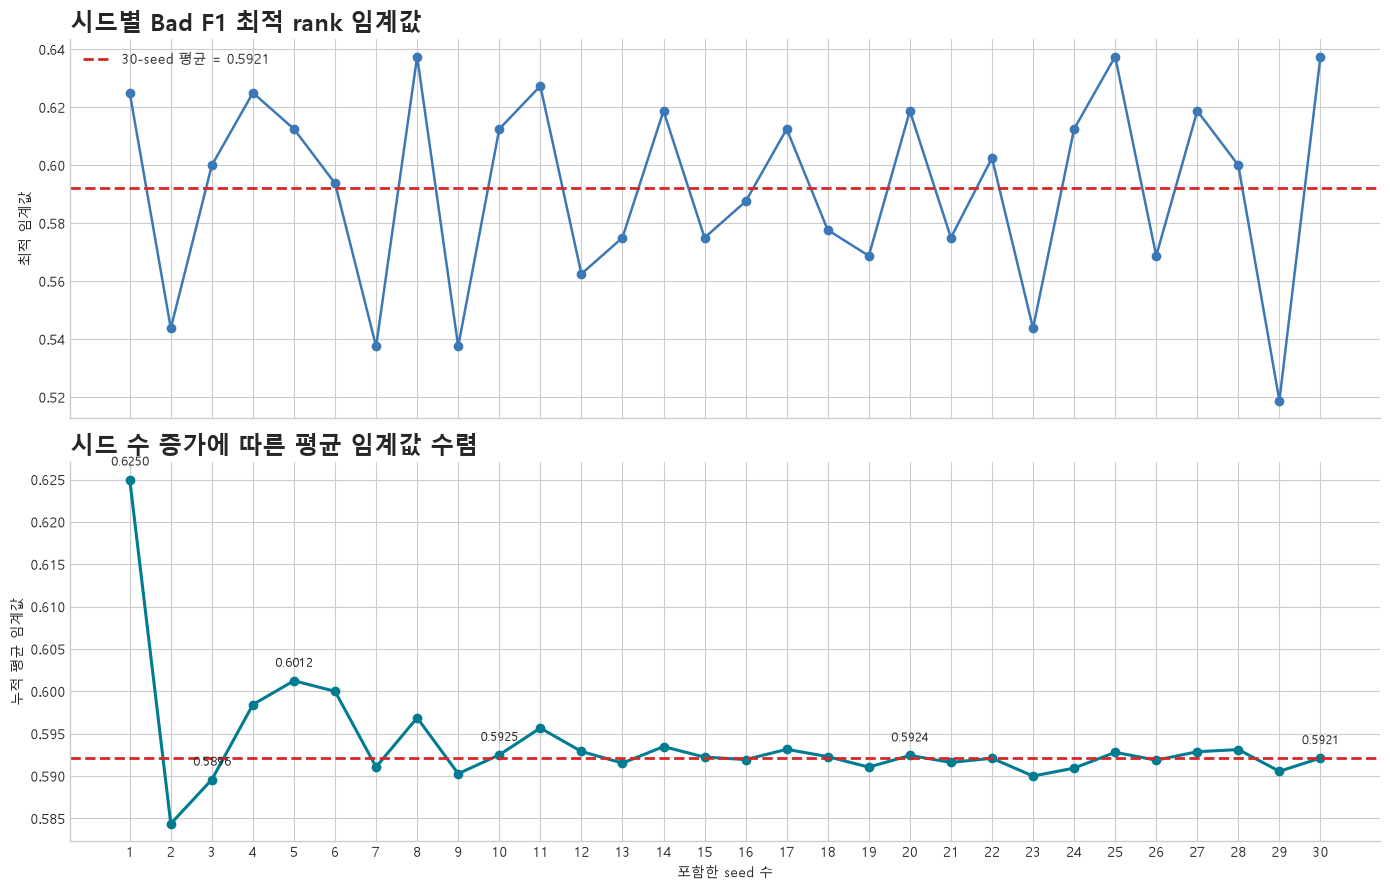

seed,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30
최적 rank 임계값,0.625000,0.543750,0.600000,0.625000,0.612500,0.593750,0.537500,0.637500,0.537500,0.612500,0.627344,0.562500,0.575000,0.618750,0.575000,0.587500,0.612500,0.577656,0.568750,0.618750,0.575000,0.602500,0.543750,0.612500,0.637500,0.568750,0.618750,0.600000,0.518750,0.637500
누적 평균,0.625000,0.584375,0.589583,0.598437,0.601250,0.600000,0.591071,0.596875,0.590278,0.592500,0.595668,0.592904,0.591526,0.593471,0.592240,0.591943,0.593153,0.592292,0.591053,0.592438,0.591607,0.592102,0.590000,0.590938,0.592800,0.591875,0.592870,0.593125,0.590560,0.592125


최종 임계값: 0.592125 → 실제 적용값 0.5921
시드별 범위: 0.518750 ~ 0.637500
예측 시 상위 40.7875%를 bad로 분류하는 경계입니다.


In [13]:
seed_numbers = np.arange(1, len(thresholds) + 1)
cumulative_mean = np.cumsum(thresholds) / seed_numbers
threshold_df = pd.DataFrame({
    'seed': seed_numbers,
    '최적 rank 임계값': thresholds,
    '누적 평균': cumulative_mean,
})

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
ax1.plot(seed_numbers, thresholds, marker='o', color='#3C78B5', lw=1.8)
ax1.axhline(thresholds.mean(), color='#D62828', ls='--', lw=2,
            label=f'{len(thresholds)}-seed 평균 = {thresholds.mean():.4f}')
ax1.set_title('시드별 Bad F1 최적 rank 임계값', loc='left', fontsize=17, fontweight='bold')
ax1.set_ylabel('최적 임계값')
ax1.legend(frameon=False)

ax2.plot(seed_numbers, cumulative_mean, marker='o', color='#007C91', lw=2.2)
ax2.axhline(thresholds.mean(), color='#D62828', ls='--', lw=2)
for n in [1, 3, 5, 10, 20, 30]:
    ax2.annotate(f'{cumulative_mean[n-1]:.4f}', (n, cumulative_mean[n-1]),
                 xytext=(0, 10), textcoords='offset points', ha='center', fontsize=9)
ax2.set_title('시드 수 증가에 따른 평균 임계값 수렴', loc='left', fontsize=17, fontweight='bold')
ax2.set_xlabel('포함한 seed 수')
ax2.set_ylabel('누적 평균 임계값')
ax2.set_xticks(seed_numbers)
sns.despine()
plt.tight_layout()
plt.show()

display(threshold_df.set_index('seed').T.style.format('{:.6f}'))
print(f'최종 임계값: {thresholds.mean():.6f} → 실제 적용값 {FINAL_THRESHOLD:.4f}')
print(f'시드별 범위: {thresholds.min():.6f} ~ {thresholds.max():.6f}')
print(f'예측 시 상위 {(1-thresholds.mean()):.4%}를 bad로 분류하는 경계입니다.')


임계값 0.50 고정   : F1 = 0.5767
임계값 0.5921 : F1 = 0.5895


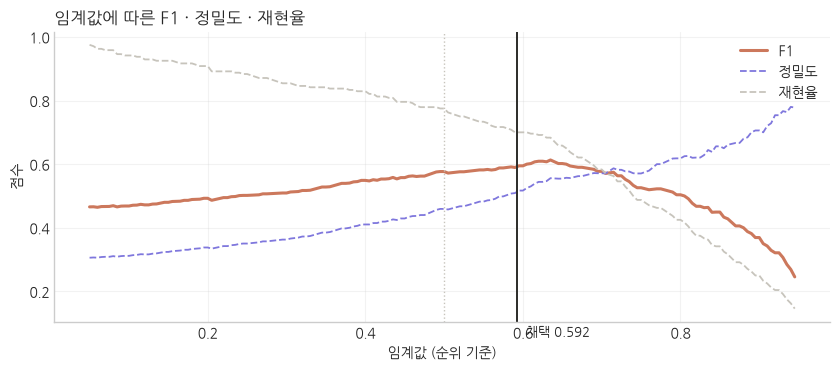

In [16]:
# 임계값에 따른 F1 곡선 (탐색 자료)
oof = oof_ranks(X, y, RANDOM_STATE)
grid = np.arange(0.05, 0.95, 0.005)
f1_curve = [f1_score(y, oof >= t) for t in grid]

print(f'임계값 0.50 고정   : F1 = {f1_score(y, oof >= 0.50):.4f}')
print(f'임계값 {FINAL_THRESHOLD:.4f} : F1 = {f1_score(y, oof >= FINAL_THRESHOLD):.4f}')

try:
    import matplotlib.pyplot as plt
    from matplotlib import font_manager
    for nm in ['NanumGothic', 'NanumBarunGothic', 'Malgun Gothic', 'AppleGothic']:
        if any(nm in f.name for f in font_manager.fontManager.ttflist):
            plt.rcParams['font.family'] = nm; break
    plt.rcParams['axes.unicode_minus'] = False

    fig, ax = plt.subplots(figsize=(8.5, 3.8))
    ax.plot(grid, f1_curve, color='#CC785C', lw=2.2, label='F1')
    ax.plot(grid, [precision_score(y, oof >= t, zero_division=0) for t in grid],
            color='#7F77DD', lw=1.3, ls='--', label='정밀도')
    ax.plot(grid, [recall_score(y, oof >= t) for t in grid],
            color='#C7C4BC', lw=1.3, ls='--', label='재현율')
    ax.axvline(FINAL_THRESHOLD, color='#2B2B28', lw=1.4)
    ax.axvline(0.5, color='#C7C4BC', lw=1, ls=':')
    ax.text(FINAL_THRESHOLD + 0.012, 0.06, f'채택 {FINAL_THRESHOLD:.3f}', fontsize=9)
    ax.set_xlabel('임계값 (순위 기준)'); ax.set_ylabel('점수')
    ax.set_title('임계값에 따른 F1 · 정밀도 · 재현율', loc='left')
    ax.legend(frameon=False); ax.grid(alpha=0.25); ax.set_axisbelow(True)
    for s in ['top', 'right']: ax.spines[s].set_visible(False)
    plt.tight_layout(); plt.show()
except Exception as e:
    print('(그래프 생략:', e, ')')

---
## 셀 10 — 최종 학습과 검증 지표

학습 데이터 전체로 최종 모델을 적합한다. 훈련 F1은 참고값일 뿐이며, 보고 성능과 클래스별 정밀도·재현율은 앞에서 만든 held-out 교차검증 결과를 사용한다.


In [17]:
final_model = make_model().fit(X, y)

r_train = rankdata(final_model.decision_function(X)) / len(X)
pred_train = (r_train >= FINAL_THRESHOLD).astype(int)

print('최종 모델 학습 완료')
print(f'  학습 표본  : {len(y)}건')
print(f'  확정 임계값: {FINAL_THRESHOLD:.4f}')
print(f'  훈련 F1 (참고) : {f1_score(y, pred_train):.4f}')
print(f'  교차검증 F1    : {m:.4f}   <- 보고 지표')
print(f'  격차           : {f1_score(y, pred_train) - m:+.4f}')


최종 모델 학습 완료
  학습 표본  : 800건
  확정 임계값: 0.5921
  훈련 F1 (참고) : 0.7019
  교차검증 F1    : 0.5836   <- 보고 지표
  격차           : +0.1183


### 최종 모델의 클래스별 정밀도·재현율

20개 시드 × 5-fold의 `cv_details`에서 직접 집계한다. 따라서 최종 모델의 교차검증 설정과 표의 수치가 항상 일치한다.


In [14]:
final_class_metrics = pd.DataFrame(
    [
        [cv_details['Good Precision'].mean(), cv_details['Bad Precision'].mean()],
        [cv_details['Good Recall'].mean(), cv_details['Bad Recall'].mean()],
    ],
    index=['정밀도 (Precision)', '재현율 (Recall)'],
    columns=['good', 'bad'],
)
display(final_class_metrics.round(4))
print(f"good 재현율: {final_class_metrics.loc['재현율 (Recall)', 'good']:.4f}")
print(f"bad  재현율: {final_class_metrics.loc['재현율 (Recall)', 'bad']:.4f}")
print(f"bad  정밀도: {final_class_metrics.loc['정밀도 (Precision)', 'bad']:.4f}")


,good,bad
정밀도 (Precision),0.8472,0.4977
재현율 (Recall),0.6932,0.7073


good 재현율: 0.6932
bad  재현율: 0.7073
bad  정밀도: 0.4977


### 최종 결과 및 예측

20개 시드 × 5-fold의 held-out 검증에서 good·bad의 정밀도, 재현율, F1을 계산한다.
F1은 각 fold에서 계산한 뒤 평균하므로 표의 평균 정밀도·재현율을 다시 조화평균한 값과는 조금 다를 수 있다.

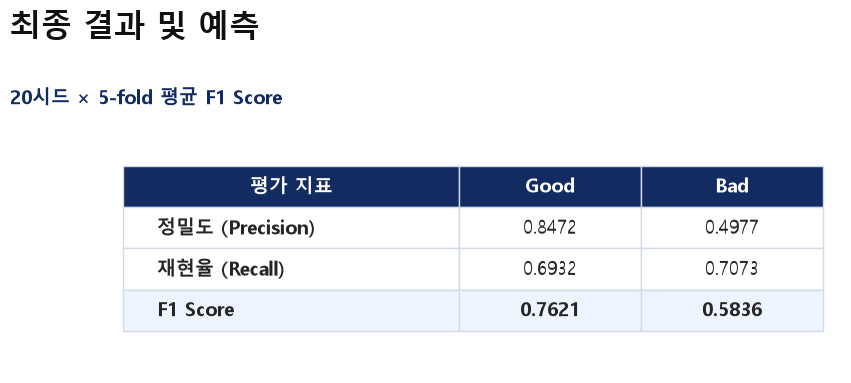

,good,bad
정밀도 (Precision),0.8472,0.4977
재현율 (Recall),0.6932,0.7073


Good F1 = 0.7621 | Bad F1 = 0.5836 (각 fold F1의 평균)


In [8]:
# 위에서 실행한 최종 SVC의 20시드 × 5-fold held-out 결과를 사용한다.
good_precision = cv_details['Good Precision'].to_numpy()
good_recall = cv_details['Good Recall'].to_numpy()
good_denominator = good_precision + good_recall
good_f1_by_fold = np.divide(
    2 * good_precision * good_recall, good_denominator,
    out=np.zeros_like(good_denominator), where=good_denominator > 0,
)
bad_precision = cv_details['Bad Precision'].to_numpy()
bad_recall = cv_details['Bad Recall'].to_numpy()
bad_denominator = bad_precision + bad_recall
bad_f1_by_fold = np.divide(
    2 * bad_precision * bad_recall, bad_denominator,
    out=np.zeros_like(bad_denominator), where=bad_denominator > 0,
)
assert np.allclose(bad_f1_by_fold, cv_details['Bad F1'].to_numpy())

class_metrics = pd.DataFrame({
    'good': [good_precision.mean(), good_recall.mean()],
    'bad': [bad_precision.mean(), bad_recall.mean()],
}, index=['정밀도 (Precision)', '재현율 (Recall)'])
good_f1 = float(good_f1_by_fold.mean())
bad_f1 = float(bad_f1_by_fold.mean())

fig, ax = plt.subplots(figsize=(9.5, 4.2))
ax.axis('off')
fig.text(.025, .91, '최종 결과 및 예측',
         fontsize=22, fontweight='bold', color='#101010')
fig.text(.025, .75, '20시드 × 5-fold 평균 F1 Score',
         fontsize=14, fontweight='bold', color='#122B60')

rows = [
    ['정밀도 (Precision)', f'{class_metrics.loc["정밀도 (Precision)", "good"]:.4f}',
     f'{class_metrics.loc["정밀도 (Precision)", "bad"]:.4f}'],
    ['재현율 (Recall)', f'{class_metrics.loc["재현율 (Recall)", "good"]:.4f}',
     f'{class_metrics.loc["재현율 (Recall)", "bad"]:.4f}'],
    ['F1 Score', f'{good_f1:.4f}', f'{bad_f1:.4f}'],
]
table = ax.table(cellText=rows, colLabels=['평가 지표', 'Good', 'Bad'],
                 cellLoc='center', colLoc='center', bbox=[.025, .13, .95, .51],
                 colWidths=[.48, .26, .26])
table.auto_set_font_size(False)
table.set_fontsize(14)
for (row, col), cell in table.get_celld().items():
    cell.set_edgecolor('#D2DAE7')
    cell.set_linewidth(1)
    if row == 0:
        cell.set_facecolor('#122B60')
        cell.set_text_props(color='white', weight='bold')
    else:
        cell.set_facecolor('#EDF4FD' if row == 3 else 'white')
        if col == 0 or row == 3:
            cell.set_text_props(weight='bold', ha='left' if col == 0 else 'center')
plt.show()

display(class_metrics.round(4))
print(f'Good F1 = {good_f1:.4f} | Bad F1 = {bad_f1:.4f} (각 fold F1의 평균)')


---
## 셀 11 — 예측 및 저장

학습과 **동일한 전처리**를 적용한 뒤 셀 9에서 확정한 임계값으로 절단한다.
임계값은 학습 데이터의 OOF 점수만으로 결정되었으며 예측 대상의 정답을 참조하지 않는다.

원본의 행 수와 칼럼 구조는 그대로 유지하고 `Risk` 칼럼만 채운다.

In [ ]:
answer_candidates = [
    Path.cwd() / '정답 입력 데이터.csv',
    Path.cwd().parent / '정답 입력 데이터.csv',
    Path.cwd() / '정답데이터.csv',
]
ANS_PATH = next((path for path in answer_candidates if path.exists()), None)

if ANS_PATH is None:
    try:
        from google.colab import files
        print('예측 대상 파일을 선택하세요.')
        uploaded = files.upload()
        ANS_PATH = Path(next(iter(uploaded)))
    except ImportError as exc:
        raise FileNotFoundError('정답 입력 데이터.csv를 현재 폴더 또는 상위 폴더에 두세요.') from exc

ans_df = pd.read_csv(ANS_PATH)
print('불러온 파일:', ANS_PATH)
print('shape:', ans_df.shape)
print('칼럼:', list(ans_df.columns))


In [ ]:
X_ans   = build_features(ans_df)
scores  = final_model.decision_function(X_ans)
ranks   = rankdata(scores) / len(scores)
pred    = (ranks >= FINAL_THRESHOLD).astype(int)

filled = ans_df.copy()
filled['Risk'] = np.where(pred == 1, 'bad', 'good')

# 무결성 확인
assert len(filled) == len(ans_df),                    '행 수 변경됨'
assert list(filled.columns) == list(ans_df.columns),  '칼럼 구조 변경됨'
assert filled['Risk'].isna().sum() == 0,              '빈 칸이 남음'

OUT_PATH = 'SVC_예측_제출.csv'
filled.to_csv(OUT_PATH, index=False, encoding='utf-8-sig')

print(f'예측 완료 — good {(pred==0).sum()}건 / bad {(pred==1).sum()}건')
print(f'bad 예측 비율 {pred.mean():.3f}  (학습셋 실제 bad율 {y.mean():.3f})')
print()
print('저장 완료:', OUT_PATH)

try:
    files.download(OUT_PATH)
except Exception:
    pass

filled.head(10)

---
## 선택 요약

| 항목 | 선택 | 근거 확인 위치 |
|---|---|---|
| 결측 처리 | 계좌 미보유 플래그로 보존 | 셀 3~5 |
| `Job` 인코딩 | 문자열 변환 후 원핫 | 시각화 1 |
| 수치 스케일링 | `StandardScaler` | 시각화 2 |
| 모델 | RBF-SVC, `C=0.5`, `gamma=0.1` | 시각화 3 및 반복검증 |
| 클래스 가중치 | 미적용 | 시각화 4 |
| 임계값 | 30개 시드 OOF 평균 | 시각화 5 |
| 보고 지표 | 20개 시드 × 5-fold held-out 결과 | 셀 8, 시각화 6~7 |

모든 결과 표와 그래프는 노트북 안에서 계산한 변수로 생성되며, 발표용 성능 수치를 별도로 입력하지 않는다.
